<a href="https://colab.research.google.com/github/dramaticforyouenjoy-sudo/RIT-Trading-Competition-2026/blob/main/Calculator.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Put in a ticker: NVDA


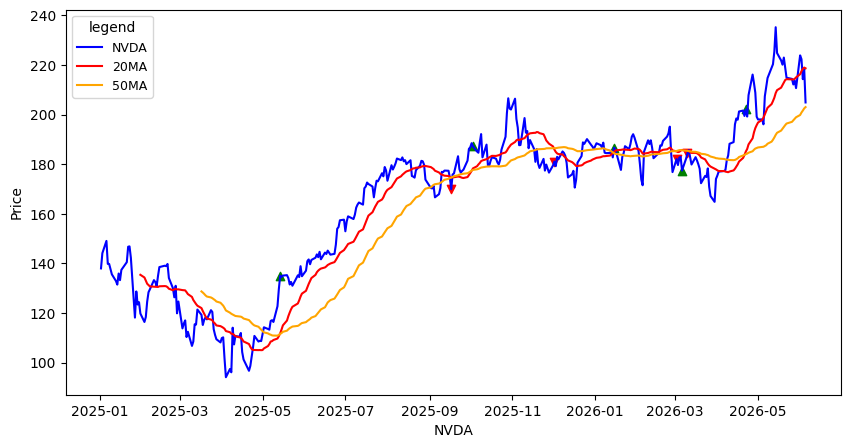

,Close,High,Low,Open,Volume,SMA_Fast,20MA,50MA,signal,position
Date,,,,,,,,,,
2025-08-20,174.970901,175.569440,168.387057,174.741468,215142700,178.254861,178.254861,165.267510,1,0.0
2025-08-21,174.551941,176.467242,173.384805,174.422269,140040900,178.316709,178.316709,165.886591,1,0.0
2025-08-22,177.554581,178.153104,170.781183,172.187737,172789400,178.540660,178.540660,166.588071,1,0.0
2025-08-25,179.370132,181.465001,176.138068,177.913713,163012800,178.693285,178.693285,167.282568,1,0.0
2025-08-26,181.325333,181.943811,178.372567,179.619509,168688200,179.005520,179.005520,168.076620,1,0.0
...,...,...,...,...,...,...,...,...,...,...
2026-06-01,223.848343,224.357174,215.208089,215.238019,212850700,216.259187,216.259187,199.808087,1,0.0
2026-06-02,222.311844,231.750261,220.845195,226.661886,193362900,217.473412,217.473412,200.808202,1,0.0
2026-06-03,214.260254,222.311857,214.020796,221.214360,160907000,218.383831,218.383831,201.588618,1,0.0


In [60]:
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
!pip install pandas-ta-classic -q
import pandas_ta_classic as ta

import warnings
warnings.filterwarnings("ignore")

chosenticker = input("Put in a ticker: ")

df = yf.download(chosenticker,start="2025-01-01",end="2026-06-06",multi_level_index=False,progress=False,auto_adjust=True)

df['20MA']= df.ta.sma(length=20,append=True,col_names=("SMA_Fast",))
df['50MA'] = df.ta.sma(length=50,append=False,col_names=("SMA_Slow",))

df['signal'] = 0
df.loc[df['20MA'] > df['50MA'], 'signal'] = 1
df.loc[df['20MA'] < df['50MA'], 'signal'] = -1

df['position'] = df['signal'].diff()

buy_signals = df[df['position'] == 2]
sell_signals = df[df['position'] == -2]

plt.figure(figsize=(10,5))
plt.plot(df.index,df['Close'],label=str(chosenticker),color='blue')
plt.plot(df.index,df['20MA'],label='20MA',color='red')
plt.plot(df.index,df['50MA'],label='50MA',color='orange')
plt.xlabel(chosenticker,fontsize=10)
plt.ylabel("Price",fontsize=10)
plt.legend(loc='upper left',title='legend',fontsize=9)

plt.scatter(buy_signals.index,buy_signals['Close'], color='green',marker='^',label='Buy signal')
plt.scatter(sell_signals.index,sell_signals['Close'],color='red',marker='v', label='Sell signal')
df.dropna()
plt.show()

df.tail(200)